<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Gradient Descent, SGD, Momentum, and Adam Comparison

This notebook covers the comparison of various optimizers:
1. Implementing Batch GD, SGD, and Momentum from scratch on a 2D loss surface.
2. Visualizing their trajectories on a 2D contour plot.
3. Training Keras models with SGD, Momentum, and Adam on a synthetic delivery-time dataset.
4. Analyzing learning rate effects and plotting losses.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

## Task 1 & 2: Scratch Implementations on a 2D Loss Surface

We define a simple quadratic function (ellipsoidal loss surface) $f(x, y) = 0.5x^2 + 2y^2$, and its gradients:
$\frac{\partial f}{\partial x} = x$, $\frac{\partial f}{\partial y} = 4y$.

In [2]:
def loss_func(x, y):
    return 0.5 * x**2 + 2.0 * y**2

def grad_func(x, y):
    return np.array([x, 4.0 * y])

# 1. Batch Gradient Descent
def batch_gd(start_pos, lr, epochs):
    pos = np.array(start_pos, dtype=float)
    path = [pos.copy()]
    for _ in range(epochs):
        grad = grad_func(pos[0], pos[1])
        pos -= lr * grad
        path.append(pos.copy())
    return np.array(path)

# 2. Stochastic Gradient Descent (with simulated noise)
def sgd_scratch(start_pos, lr, epochs, noise_std=0.2):
    pos = np.array(start_pos, dtype=float)
    path = [pos.copy()]
    for _ in range(epochs):
        # Add artificial noise to simulate mini-batch/stochastic gradients
        noise = np.random.normal(0, noise_std, size=2)
        grad = grad_func(pos[0], pos[1]) + noise
        pos -= lr * grad
        path.append(pos.copy())
    return np.array(path)

# 3. Momentum Gradient Descent
def momentum_gd(start_pos, lr, beta, epochs):
    pos = np.array(start_pos, dtype=float)
    velocity = np.zeros_like(pos)
    path = [pos.copy()]
    for _ in range(epochs):
        grad = grad_func(pos[0], pos[1])
        velocity = beta * velocity + lr * grad
        pos -= velocity
        path.append(pos.copy())
    return np.array(path)

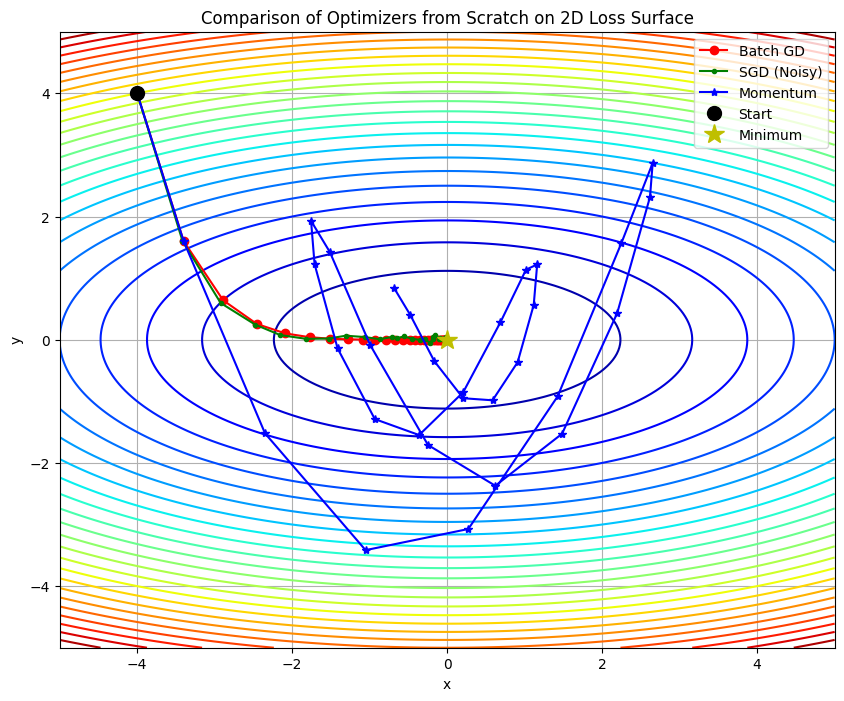

In [3]:
# Optimization Parameters
start_position = [-4.0, 4.0]
epochs = 30
learning_rate = 0.15
beta = 0.9

path_gd = batch_gd(start_position, learning_rate, epochs)
path_sgd = sgd_scratch(start_position, learning_rate, epochs)
path_momentum = momentum_gd(start_position, learning_rate, beta, epochs)

# Plotting trajectories on contour lines
x_vals = np.linspace(-5, 5, 200)
y_vals = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x_vals, y_vals)
Z = loss_func(X, Y)

plt.figure(figsize=(10, 8))
plt.contour(X, Y, Z, levels=25, cmap='jet')
plt.plot(path_gd[:, 0], path_gd[:, 1], 'ro-', label='Batch GD')
plt.plot(path_sgd[:, 0], path_sgd[:, 1], 'g.-', label='SGD (Noisy)')
plt.plot(path_momentum[:, 0], path_momentum[:, 1], 'b*-', label='Momentum')
plt.plot(start_position[0], start_position[1], 'ko', markersize=10, label='Start')
plt.plot(0, 0, 'y*', markersize=15, label='Minimum')

plt.title('Comparison of Optimizers from Scratch on 2D Loss Surface')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

## Task 3 & 4: Train Keras regression model with SGD, Momentum, and Adam

We generate a synthetic Delivery Dataset with delivery distance, traffic index, weight, and time of day, and then compare Keras optimizers on a regression task.

In [4]:
# Generate synthetic Delivery Dataset
num_samples = 2000
distance = np.random.uniform(5, 50, num_samples) # km
traffic_index = np.random.uniform(1, 10, num_samples) # 1-10 congestion scale
weight = np.random.uniform(1, 50, num_samples) # kg
time_of_day = np.random.uniform(0, 24, num_samples) # hour

# Assume a true non-linear delivery time model with some noise
delivery_time = (0.8 * distance + 2.5 * traffic_index + 0.05 * weight +
                 1.5 * np.sin(time_of_day * np.pi / 12) + 10 + np.random.normal(0, 2, num_samples))

X_data = np.stack([distance, traffic_index, weight, time_of_day], axis=1)
Y_data = delivery_time

# Split into Train and Validation
split = int(0.8 * num_samples)
X_train, X_val = X_data[:split], X_data[split:]
y_train, y_val = Y_data[:split], Y_data[split:]

# Normalize features
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
X_train_norm = (X_train - mean) / std
X_val_norm = (X_val - mean) / std

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


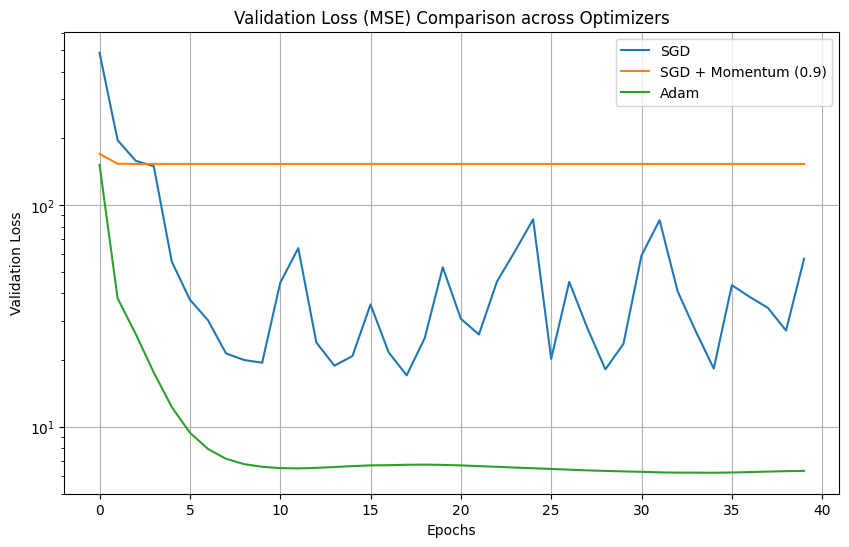

In [5]:
def build_model():
    model = keras.Sequential([
        layers.Dense(32, activation='relu', input_shape=(4,)),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ])
    return model

# Train configurations
keras_epochs = 40
batch_size = 32

# Model 1: Plain SGD
model_sgd = build_model()
model_sgd.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01), loss='mse')
history_sgd = model_sgd.fit(X_train_norm, y_train, validation_data=(X_val_norm, y_val),
                            epochs=keras_epochs, batch_size=batch_size, verbose=0)

# Model 2: SGD with Momentum
model_momentum = build_model()
model_momentum.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), loss='mse')
history_momentum = model_momentum.fit(X_train_norm, y_train, validation_data=(X_val_norm, y_val),
                                     epochs=keras_epochs, batch_size=batch_size, verbose=0)

# Model 3: Adam
model_adam = build_model()
model_adam.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mse')
history_adam = model_adam.fit(X_train_norm, y_train, validation_data=(X_val_norm, y_val),
                                 epochs=keras_epochs, batch_size=batch_size, verbose=0)

# Plot validation loss against epochs
plt.figure(figsize=(10, 6))
plt.plot(history_sgd.history['val_loss'], label='SGD')
plt.plot(history_momentum.history['val_loss'], label='SGD + Momentum (0.9)')
plt.plot(history_adam.history['val_loss'], label='Adam')
plt.title('Validation Loss (MSE) Comparison across Optimizers')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.show()

## Task 5: Vary Learning Rate and Observe Convergence/Divergence

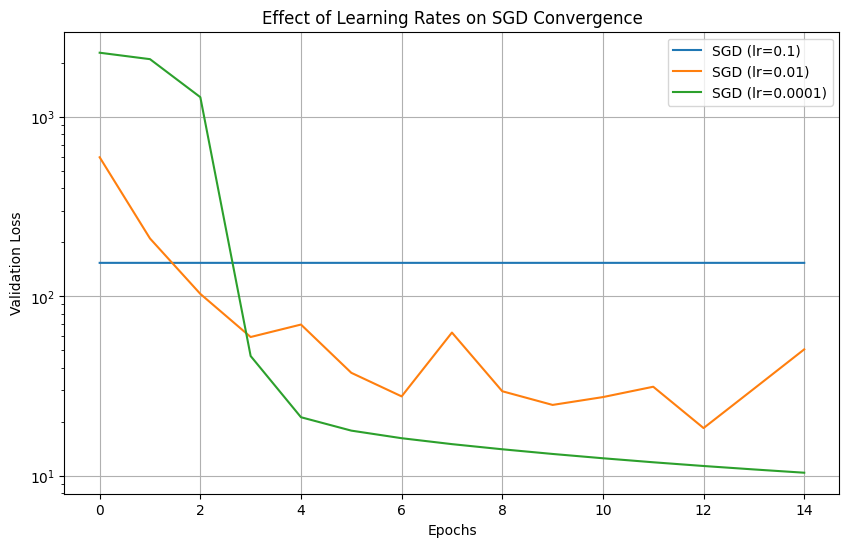

In [6]:
learning_rates = [0.1, 0.01, 0.0001]
histories = {}

for lr in learning_rates:
    model_tmp = build_model()
    model_tmp.compile(optimizer=keras.optimizers.SGD(learning_rate=lr), loss='mse')
    hist = model_tmp.fit(X_train_norm, y_train, validation_data=(X_val_norm, y_val),
                         epochs=15, batch_size=32, verbose=0)
    histories[lr] = hist.history['val_loss']

# Plot comparisons for varying learning rates
plt.figure(figsize=(10, 6))
for lr, losses in histories.items():
    plt.plot(losses, label=f'SGD (lr={lr})')
plt.title('Effect of Learning Rates on SGD Convergence')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.show()